# MobileNetV2 en Colab — PlantVillage (datos reales, transfer learning)

Notebook autocontenido para Google Colab. **No depende del paquete instalado ni de archivos locales del proyecto**: incluye la descarga del dataset, la configuración (`settings.py`), la carga de datos (`data.py`) y el entrenamiento con MobileNetV2 pre-entrenado (`mobilenet.py`).

Sigue la guía de TensorFlow: https://www.tensorflow.org/tutorials/images/transfer_learning

Runtime recomendado: **GPU** (Runtime → Cambiar tipo de runtime → GPU).


In [1]:
# 0. Instalar dependencias
!pip -q install tensorflow mlflow codecarbon


In [2]:
# 1. Descargar el dataset real de PlantVillage (script de descarga del proyecto)
import os, shutil, subprocess
from pathlib import Path

WORK = Path("/content/leafthealthvision")
DATA_DIR = WORK / "data" / "plantvillage"
REPO_URL = "https://github.com/spMohanty/PlantVillage-Dataset.git"

if not DATA_DIR.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    print(f"Clonando {REPO_URL} ...")
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(DATA_DIR)],
        check=True,
    )
    # Quitar .git anidado
    git_dir = DATA_DIR / ".git"
    if git_dir.exists():
        shutil.rmtree(git_dir)
    # Conservar solo lo necesario: raw/color y metadata
    for item in DATA_DIR.iterdir():
        if item.name not in {
            "raw",
            "leaf_grouping",
            "leaf-map.json",
            "README.md",
            "CITATION.cff",
        }:
            if item.is_dir():
                shutil.rmtree(item)
            else:
                item.unlink()
    print("Dataset listo en:", DATA_DIR)
else:
    print("Dataset ya descargado en:", DATA_DIR)

data_dir = DATA_DIR / "raw" / "color"
print("Imágenes en:", data_dir)
print("Clases encontradas:", len([p for p in data_dir.iterdir() if p.is_dir()]))


Clonando https://github.com/spMohanty/PlantVillage-Dataset.git ...
Dataset listo en: /content/leafthealthvision/data/plantvillage
Imágenes en: /content/leafthealthvision/data/plantvillage/raw/color
Clases encontradas: 38


In [3]:
# 2. Configuración (equivalente a src/leafthealthvision/config/settings.py)
import tensorflow as tf

# Configurar GPU ANTES de cualquier otra operación de TensorFlow
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        # Mixed precision: más rápido en Tensor Cores y menos VRAM
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        print(f"GPU activada: {len(gpus)} dispositivo(s), mixed_float16")
    except RuntimeError as e:
        print(f"Nota GPU (ya inicializada): {e}")
else:
    print("No se detectó GPU; se usará CPU")

import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import applications, layers, models
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model

SEED = 42
BATCH_SIZE = 620
IMAGE_TARGET_SIZE = (224, 224)
IMAGE_RESCALE = 1.0 / 255.0
OPTIMIZER = "adam"
METRICS = ["accuracy"]
EARLY_STOPPING_PATIENCE = 5
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.1
EPOCHS = 10

CLASS_NAMES = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Raspberry___healthy",
    "Soybean___healthy",
    "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch",
    "Strawberry___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy",
]

tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("Config cargada. Imagen objetivo:", IMAGE_TARGET_SIZE, "| Batch:", BATCH_SIZE)


GPU activada: 1 dispositivo(s), mixed_float16
Config cargada. Imagen objetivo: (224, 224) | Batch: 620


In [4]:
# MLflow: seguimiento del experimento (se guarda en ./mlruns del entorno)
import mlflow
import mlflow.tensorflow
import json
from codecarbon import EmissionsTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("leafthealthvision")


class MlflowEpochLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        mlflow.log_metrics({k: float(v) for k, v in logs.items()}, step=epoch)


2026/11/27 19:34:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/27 19:34:17 INFO mlflow.store.db.utils: Updating database tables
2026/11/27 19:34:20 INFO mlflow.tracking.fluent: Experiment with name 'leafthealthvision' does not exist. Creating a new experiment.


In [5]:
# 3. Cargar datasets (equivalente a src/leafthealthvision/data.py, adaptado a Colab)
def load_datasets(
    data_dir, batch_size, img_size, seed, train_split=TRAIN_SPLIT, val_split=VAL_SPLIT
):
    full_dataset = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        label_mode="int",
        image_size=img_size,
        batch_size=batch_size,
        seed=seed,
    )
    class_names = full_dataset.class_names
    assert class_names == CLASS_NAMES, "Las clases del dataset no coinciden"
    # Sin .cache() (evita cargar ~100 GB en RAM) y shuffle buffer pequeño
    full_dataset = full_dataset.shuffle(
        buffer_size=32, seed=seed, reshuffle_each_iteration=False
    )

    n_batches = int(full_dataset.cardinality().numpy())
    n_train = int(n_batches * train_split)
    n_val = int(n_batches * val_split)

    train_dataset = full_dataset.take(n_train)
    rest = full_dataset.skip(n_train)
    validation_dataset = rest.take(n_val)
    test_dataset = rest.skip(n_val)

    train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
    validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

    return train_dataset, validation_dataset, test_dataset, class_names


train_ds, validation_ds, test_ds, class_names = load_datasets(
    data_dir=data_dir,
    batch_size=BATCH_SIZE,
    img_size=IMAGE_TARGET_SIZE,
    seed=SEED,
)

print("Clases:", len(class_names))
print("Train batches:", train_ds.cardinality().numpy())
print("Val batches:", validation_ds.cardinality().numpy())
print("Test batches:", test_ds.cardinality().numpy())


Found 54305 files belonging to 38 classes.
Clases: 38
Train batches: 70
Val batches: 8
Test batches: 10


In [ ]:
# Pesos por clase calculados solo con train: N / (K * n_clase)
from collections import Counter
train_labels = np.concatenate([labels.numpy() for _, labels in train_ds], axis=0)
counts = Counter(train_labels.tolist())
class_weight = {c: len(train_labels) / (len(class_names) * n) for c, n in counts.items()}
print("Pesos por clase:", {k: round(v, 4) for k, v in sorted(class_weight.items())})


In [6]:
# 4. Modelo con transfer learning MobileNetV2 (equivalente a src/leafthealthvision/training/mobilenet.py)
img_height, img_width = IMAGE_TARGET_SIZE
num_classes = len(class_names)

# Base pre-entrenada de MobileNetV2 sin la cabeza (include_top=False)
base_model = applications.MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet",
)

# Congelar la base: solo se entrena la cabeza nueva
base_model.trainable = False

inputs = Input(shape=(img_height, img_width, 3))
x = layers.Rescaling(IMAGE_RESCALE)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(num_classes)(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=OPTIMIZER,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=METRICS,
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# 5. Entrenar con EarlyStopping (con MLflow y huella de carbono)
early_stop = tf.keras.callbacks.EarlyStopping(
    patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
)

tracker = EmissionsTracker(save_to_file=False)

with mlflow.start_run(run_name="mobilenetv2_transfer_learning") as run:
    mlflow.log_param("class_names", json.dumps(CLASS_NAMES))
    mlflow.log_params(
        {
            "model": "mobilenetv2",
            "base_model_weights": "imagenet",
            "base_trainable": False,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "img_height": img_height,
            "img_width": img_width,
            "image_rescale": IMAGE_RESCALE,
            "optimizer": OPTIMIZER,
            "loss": "SparseCategoricalCrossentropy(from_logits=True)",
            "metrics": ",".join(METRICS),
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "num_classes": len(class_names),
        }
    )

tracker.start()
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=[early_stop, MlflowEpochLogger()],
)

emisiones_kg = tracker.stop() or 0.0
energia_kwh = getattr(getattr(tracker, "_total_energy", None), "kWh", None)

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

final_metrics = {
    "final_accuracy": float(acc[-1]),
    "final_val_accuracy": float(val_acc[-1]),
    "final_loss": float(loss[-1]),
    "final_val_loss": float(val_loss[-1]),
    "carbon_emissions_kg": float(emisiones_kg),
}
if energia_kwh is not None:
    final_metrics["energy_consumed_kwh"] = float(energia_kwh)
mlflow.log_metrics(final_metrics)

try:
    mlflow.tensorflow.log_model(model, name="model")
except Exception as exc:
    print(f"No se pudo registrar el modelo en MLflow: {exc}")

print(f"Huella de carbono del entrenamiento: {emisiones_kg:.6f} kg CO2eq")


[codecarbon WARNING @ 19:34:27] Multiple instances of codecarbon are allowed to run at the same time.
/tmp/ipykernel_778/503457646.py:6: FutureWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  tracker = EmissionsTracker(save_to_file=False)
[codecarbon INFO @ 19:34:27] [setup] RAM Tracking...
[codecarbon INFO @ 19:34:27] [setup] CPU Tracking...
[codecarbon INFO @ 19:34:27] [setup] GPU Tracking...
[codecarbon INFO @ 19:34:27] Tracking Nvidia GPUs via PyNVML
[codecarbon WARNING @ 19:34:28] We saw that you have a Intel(R) Xeon(R) CPU @ 2.00GHz but we don't know it. Please help us add it, see https://docs.codecarbon.io/latest/how-to/troubleshooting/#unknown-cpu-model
[codecarbon WARNING @ 19:34:28] We will use the default power consumption of 4 W per thread for your 8 CPU, so 32W.
[codecarbon WARNING @ 19:34:28] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Linux OS

Epoch 1/10


[codecarbon INFO @ 19:34:43] Energy consumed for RAM : 0.000083 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 19:34:43] Energy consumed for all GPUs : 0.000134 kWh. Total GPU Power : 31.932820698648015 W
[codecarbon INFO @ 19:34:43] Delta energy consumed for CPU with cpu_load : 0.000023 kWh, power : 5.609937245760271 W
[codecarbon INFO @ 19:34:43] Energy consumed for All CPU : 0.000023 kWh
[codecarbon INFO @ 19:34:43] 0.000241 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 19:34:58] Energy consumed for RAM : 0.000167 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 19:34:58] Energy consumed for all GPUs : 0.000368 kWh. Total GPU Power : 56.28413606459922 W
[codecarbon INFO @ 19:34:58] Delta energy consumed for CPU with cpu_load : 0.000023 kWh, power : 5.509628902294275 W
[codecarbon INFO @ 19:34:58] Energy consumed for All CPU : 0.000046 kWh
[codecarbon INFO @ 19:34:58] 0.000581 kWh of electricity and 0.000000 L of water were used since the beginnin

31/70 ━━━━━━━━━━━━━━━━━━━━ 9s 234ms/step - accuracy: 0.2793 - loss: 2.8133

[codecarbon INFO @ 19:35:43] Energy consumed for RAM : 0.000416 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 19:35:43] Energy consumed for all GPUs : 0.001142 kWh. Total GPU Power : 54.94019087442376 W
[codecarbon INFO @ 19:35:43] Delta energy consumed for CPU with cpu_load : 0.000022 kWh, power : 5.24083844345692 W
[codecarbon INFO @ 19:35:43] Energy consumed for All CPU : 0.000096 kWh
[codecarbon INFO @ 19:35:43] 0.001655 kWh of electricity and 0.000000 L of water were used since the beginning.


70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.4608 - loss: 2.1468

... (44 outputs left out)

[codecarbon INFO @ 19:41:28] Energy consumed for RAM : 0.002331 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 19:41:28] Energy consumed for all GPUs : 0.006111 kWh. Total GPU Power : 62.37858137277166 W
[codecarbon INFO @ 19:41:28] Delta energy consumed for CPU with cpu_load : 0.000025 kWh, power : 6.119179153984324 W
[codecarbon INFO @ 19:41:28] Energy consumed for All CPU : 0.001169 kWh
[codecarbon INFO @ 19:41:28] 0.009611 kWh of electricity and 0.000000 L of water were used since the beginning.


70/70 ━━━━━━━━━━━━━━━━━━━━ 36s 457ms/step - accuracy: 0.9663 - loss: 0.1294 - val_accuracy: 0.9627 - val_loss: 0.1358


[codecarbon INFO @ 19:41:42] Energy consumed for RAM : 0.002406 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 19:41:42] Energy consumed for all GPUs : 0.006263 kWh. Total GPU Power : 40.79228633993726 W
[codecarbon INFO @ 19:41:42] Delta energy consumed for CPU with cpu_load : 0.000057 kWh, power : 15.456666819204168 W
[codecarbon INFO @ 19:41:42] Energy consumed for All CPU : 0.001226 kWh
[codecarbon INFO @ 19:41:42] 0.009894 kWh of electricity and 0.000000 L of water were used since the beginning.
2026/11/27 19:41:42 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


Huella de carbono del entrenamiento: 0.002509 kg CO2eq


In [ ]:
# 6. Evaluación en test: métricas, matriz de confusión y reporte
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
probabilities = model.predict(test_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)
macro = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
weighted = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
metrics = {
    'accuracy': float(np.mean(y_true == y_pred)),
    'precision_macro': float(macro[0]),
    'recall_macro': float(macro[1]),
    'f1_macro': float(macro[2]),
    'precision_weighted': float(weighted[0]),
    'recall_weighted': float(weighted[1]),
    'f1_weighted': float(weighted[2]),
}

matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
figure, axis = plt.subplots(figsize=(14, 12))
image = axis.imshow(matrix, interpolation='nearest', cmap='Blues')
figure.colorbar(image, ax=axis)
axis.set(xticks=np.arange(len(class_names)), yticks=np.arange(len(class_names)),
     xlabel='Predicción', ylabel='Clase real', title='Matriz de confusión — test')
axis.set_xticklabels(class_names, rotation=90, fontsize=6)
axis.set_yticklabels(class_names, fontsize=6)
figure.tight_layout()
matrix_path = WORK / 'artifacts' / 'confusion_matrix_test.png'
matrix_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(matrix_path, dpi=150)
plt.show()
plt.close(figure)

report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
report_path = WORK / 'artifacts' / 'classification_report_test.txt'
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(report, encoding='utf-8')

mlflow.log_artifact(str(matrix_path), artifact_path='evaluation')
mlflow.log_artifact(str(report_path), artifact_path='evaluation')
mlflow.log_metrics({f'test_{k}': v for k, v in metrics.items()})
print('--- test ---')
print(report)


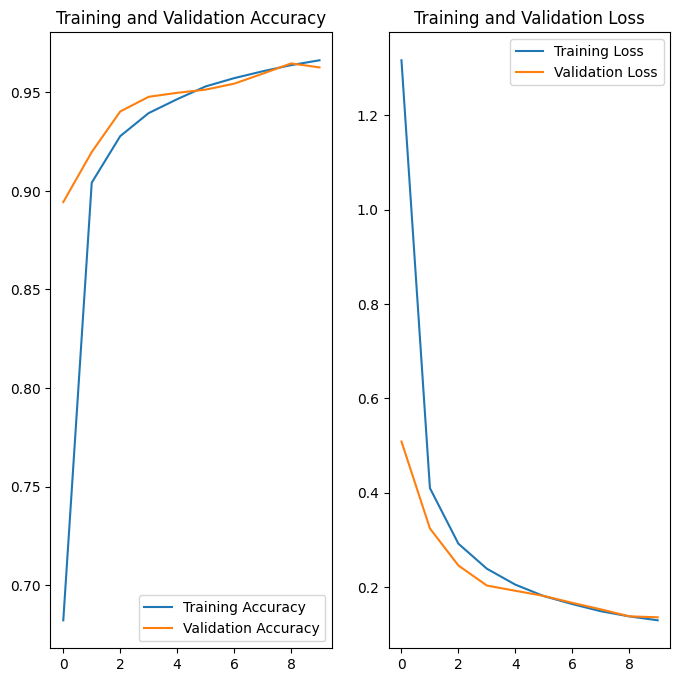

In [8]:
# 6. Graficar accuracy y loss
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(len(acc))

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.show()


In [9]:
!curl https://static.vecteezy.com/system/resources/previews/011/855/781/non_2x/green-leaf-of-apple-tree-photo.jpg --output test.jpg

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  107k  100  107k    0     0  1037k      0 --:--:-- --:--:-- --:--:-- 1048k


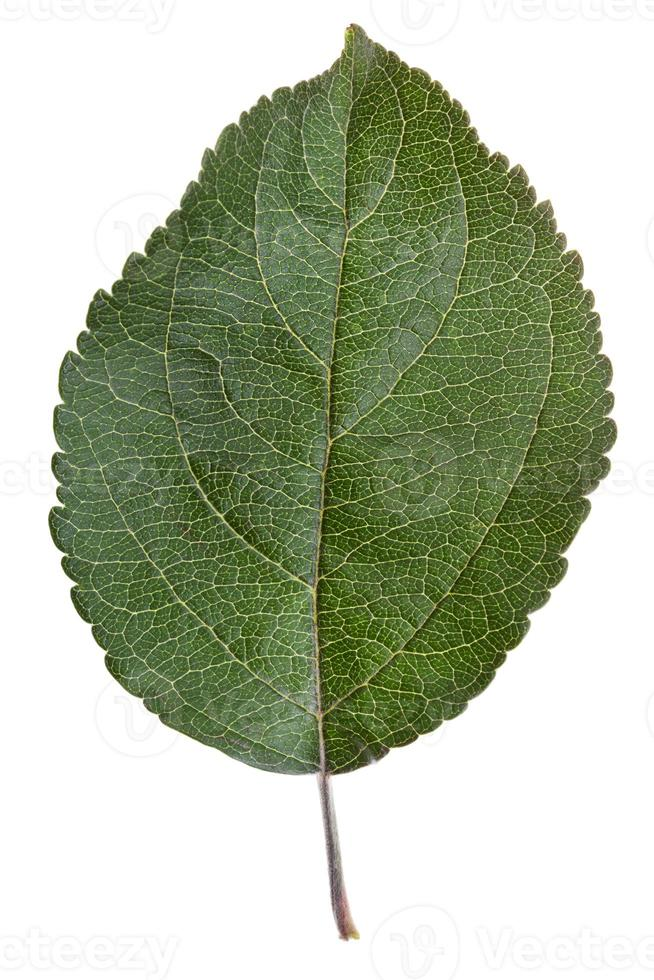

In [10]:
from PIL import Image
from IPython.display import display

imagen = Image.open("/content/test.jpg")
display(imagen)

In [11]:
img = tf.keras.utils.load_img("/content/test.jpg", target_size=(img_height, img_width))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create a batch

predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

print(
    f"This image most likely belongs to {class_names[np.argmax(score)]} with a {100 * np.max(score):.2f} percent confidence."
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
This image most likely belongs to Apple___healthy with a 90.06 percent confidence.


## 7. Inferencia con el modelo entrenado y mapa de calor (Grad-CAM)

Se recupera el modelo registrado en MLflow durante el entrenamiento y Grad-CAM resalta la región de la hoja que más aporta a la clase predicha. Además se mide latencia, energía y emisiones, y se guarda cada inferencia en `results/inference_cost.csv`.


[codecarbon WARNING @ 19:42:08] Multiple instances of codecarbon are allowed to run at the same time.
/tmp/ipykernel_778/3563364909.py:5: FutureWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  tracker = EmissionsTracker(save_to_file=False, log_level='ERROR')


Apple___healthy: 90.08%
Latencia: 17.293 s | Energía: 0.0002909332091346297 kWh | Emisiones: 0.000073769 kg CO2eq
Registro guardado en: /content/leafthealthvision/results/inference_cost.csv


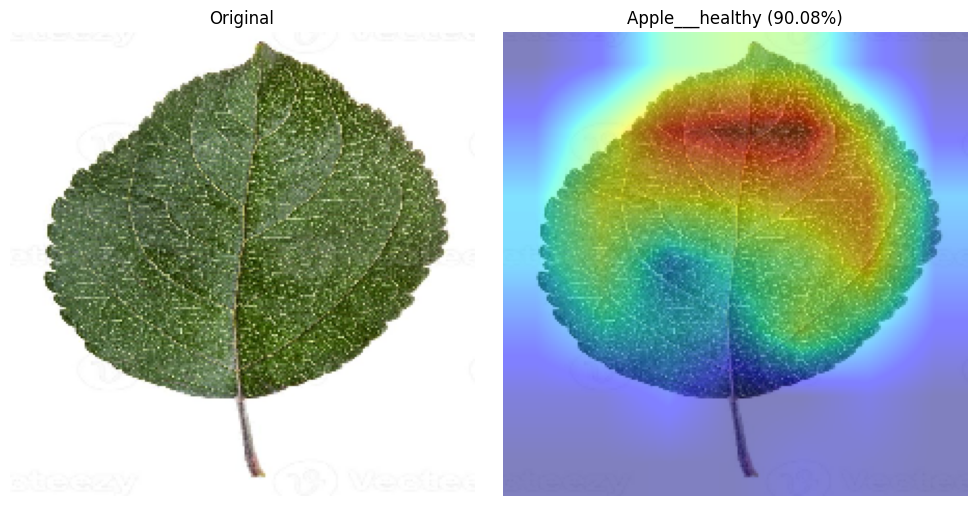

In [12]:
# 7. Inferencia desde el modelo registrado en MLflow + Grad-CAM
import csv, time
from datetime import datetime, timezone

tracker = EmissionsTracker(save_to_file=False, log_level='ERROR')
tracker.start()
start = time.perf_counter()
try:
    image = tf.keras.utils.load_img("/content/test.jpg", target_size=IMAGE_TARGET_SIZE)
    batch = np.expand_dims(tf.keras.utils.img_to_array(image), 0)  # el modelo incluye Rescaling

    def last_convolution(m):
        conv_layers = []
        def walk(current):
            for layer in current.layers:
                if isinstance(layer, tf.keras.Model):
                    walk(layer)
                elif len(layer.output.shape) == 4:
                    conv_layers.append(layer)
        walk(m)
        return conv_layers[-1]

    layer = last_convolution(model)
    activations = {}
    original_call = layer.call

    def capture(*args, **kwargs):
        output = original_call(*args, **kwargs)
        activations['feature_map'] = output
        return output

    layer.call = capture
    try:
        with tf.GradientTape() as tape:
            predictions = model(batch, training=False)
            probabilities = tf.nn.softmax(tf.cast(predictions, 'float32'))[0]
            index = int(tf.argmax(probabilities))
            score = tf.cast(predictions[0, index], 'float32')
            feature_map = activations['feature_map']
    finally:
        layer.call = original_call

    gradients = tape.gradient(score, feature_map)
    weights = tf.reduce_mean(tf.cast(gradients, 'float32'), axis=(1, 2))
    cam = tf.reduce_sum(tf.cast(feature_map, 'float32') * weights[:, None, None, :], axis=-1)
    cam = tf.nn.relu(cam)[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    heatmap = tf.image.resize(cam[..., None], IMAGE_TARGET_SIZE)[..., 0].numpy()

    predicted_class = class_names[index]
    confidence = float(probabilities[index].numpy())
finally:
    latency_s = time.perf_counter() - start
    emissions_kg = tracker.stop() or 0.0

energy_kwh = getattr(getattr(tracker, '_total_energy', None), 'kWh', None)

header = ['timestamp', 'image', 'model', 'class', 'confidence', 'latency_s', 'energy_kwh', 'emissions_kg']
record = {
    'timestamp': datetime.now(timezone.utc).isoformat(),
    'image': '/content/test.jpg',
    'model': model.name,
    'class': predicted_class,
    'confidence': confidence,
    'latency_s': latency_s,
    'energy_kwh': energy_kwh,
    'emissions_kg': emissions_kg,
}
file_path = WORK / 'results' / 'inference_cost.csv'
file_path.parent.mkdir(parents=True, exist_ok=True)
existed = file_path.exists()
with file_path.open('a', newline='') as file_handle:
    writer = csv.DictWriter(file_handle, fieldnames=header)
    if not existed:
        writer.writeheader()
    writer.writerow(record)

print(f'{predicted_class}: {confidence:.2%}')
print(f"Latencia: {latency_s:.3f} s | Energía: {energy_kwh} kWh | Emisiones: {emissions_kg:.9f} kg CO2eq")
print('Registro guardado en:', file_path)

fig, (ax_original, ax_heatmap) = plt.subplots(1, 2, figsize=(10, 5))
ax_original.imshow(image)
ax_original.set_title('Original')
ax_heatmap.imshow(image)
ax_heatmap.imshow(heatmap, cmap='jet', alpha=0.5)
ax_heatmap.set_title(f'{predicted_class} ({confidence:.2%})')
for ax in (ax_original, ax_heatmap):
    ax.axis('off')
plt.tight_layout()
plt.show()
